# Applying Connectome Spectrum Electromagnetic Tomography (CSET) on individual data

CSET solves the following optimization problem: 
$$\hat {\mathbf s}^* = \underset{\hat{\mathbf s}}{\text{argmin}} \lVert \mathbf{LU}\hat{\mathbf s}-\mathbf{y} \rVert_2^2 + \lambda \lVert \hat{\mathbf s}\rVert_1$$
$$ \mathbf s^* = \mathbf U \hat{\mathbf s}^*$$

where
- $\mathbf{s}^* \in \mathbb{R}^n$ are the reconstructed dipole strengths
- $\hat{\mathbf{s}}^* \in \mathbb{R}^n$ is the reconstructed connectome spectrum.
- $\mathbf{y} \in \mathbb{R}^m$ are the EEG measurements.
- $\mathbf L \in \mathbb{R}^{m\times n}$ is the lead field matrix.
- $\mathbf U \in \mathbb{R}^{n \times n}$ is the inverse graph Fourier transform
- $\lambda \in \mathbb{R}$ is the regularizer parameter.

Regularizing with $\lVert \hat {\mathbf s}\rVert_1$ imposes the connectome spectrum to be sparse.

## 📦 Imports

In [1]:
import mindmap as mm
import mne
import numpy as np
from pathlib import Path

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- `eeg`: Preprocessed EEG
- `fwd`: Forward operator
- `cst`: Connectome spectrum transform
- `gt`: Ground Truth (optional)
- `resec`: Resection area 

In [2]:
################# Parameters ###################
# configuration
fconfig = "../../papers/spike/configuration.yml"
sub     = 25
samp    = 0
#################################################

# configuration
reader = mm.io.dataset_reader(fconfig)
mm_dir = reader.config["MM_DIR"]

# data
data = reader(sub, "eeg", "fwd", "cst", "gt", "resec", sample=samp)

# fix lead field orientation
fwd = mne.convert_forward_solution(data["fwd"], force_fixed=True, verbose="warning")
fwd = fwd["sol"]["data"].astype("float64")

# time of interest
hrp_time  = mm.utils.eeg_rising_phase(data["eeg"], ratio=0.5)    # half rising phase
peak_time = mm.utils.eeg_rising_phase(data["eeg"], ratio=1)      # peak phase

print(f"50% rising phase time: {hrp_time:03} [s]")
print(f"Peak phase time: {peak_time:03} [s]")

DATA SUMMARY
Dataset: spike
Subject: sub-pat25
Retrieved objects:
- fwd
- resec
- eeg
- cst
Missing objects:
- gt
50% rising phase time: 0.476 [s]
Peak phase time: 0.496 [s]


## EEG

🌟 **Visualize EEG topographic maps at 50% rising phase and peak phase**

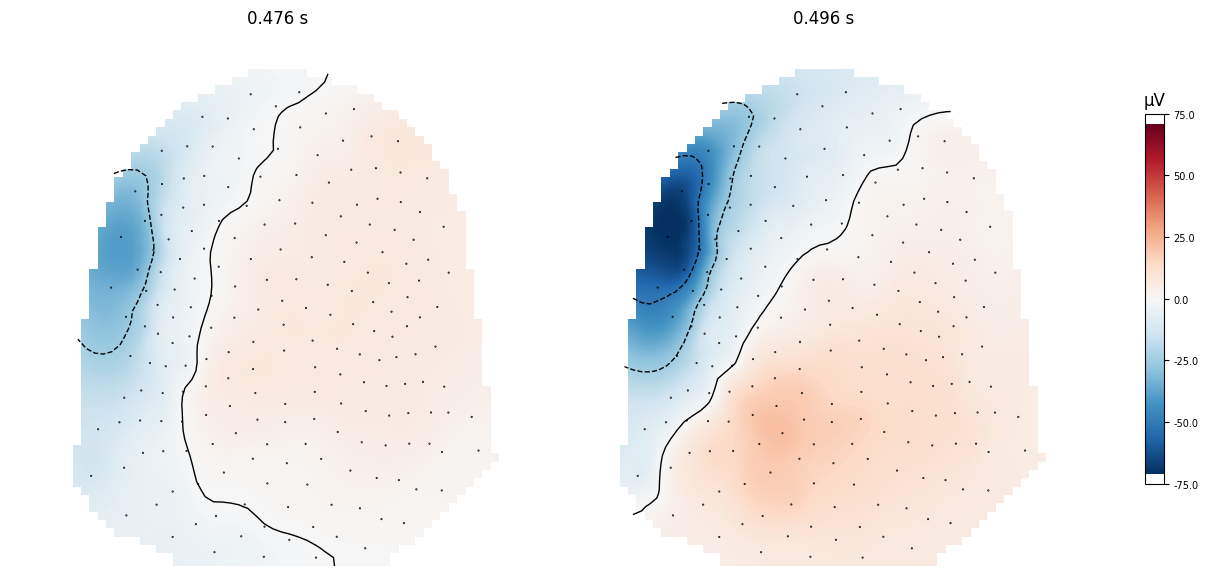

In [3]:
times = [hrp_time, peak_time]
_ = data["eeg"].plot_topomap(times=times, size=4, extrapolate="local", outlines=None)

🛠️ <font color=violet>**Time window**</font>:
- `win_size`: time window around EEG peak in [s]

Number of samples: 77


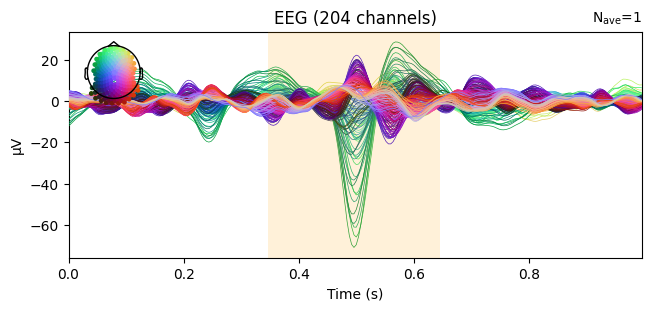

In [4]:
########### Parameters ###############
win_size = 0.3
######################################

window    = data["eeg"].copy()
highlight = None

if win_size is not None:
    dt = win_size/2 
    window = window.crop(peak_time-dt, peak_time+dt)

    highlight = [peak_time-dt, peak_time+dt]

print(f"Number of samples: {len(window.times)}")
_ = data["eeg"].plot(highlight=highlight)

## Compute CSET solution

#### ⚙️ <font color=green>**Apply CSET**</font>
Using the `pyxu` package we can write down any optimization problem and then solve them.

🛠️ <font color=violet>**CSET**</font> 
- `lam` ($\lambda$): regularizer parameter (influences the connectome spectrum sparsity)
- `dw`: depth weighting coefficient 

In [5]:
############## Parameters #############
lam = 0.01
dw  = 1/2 
#######################################

stc = mm.inverse.cset(
    eeg = window,
    fwd = data["fwd"],
    cst = data["cst"],
    lam = lam,
    dw  = dw,
)

print("\033[92mReconstruction finished\033[0m")

Reconstruction finished


🌟 **Visualize reconstructed dipole strengths** <br>

In [8]:
try:
    overlay = data["resec"]
except:
    overlay = None 

try: 
    ground_truth = data["gt"]
    ground_truth = ground_truth.crop(stc.times[0], stc.times[-1])
    signals = [stc, ground_truth]
    titles  = ["CSET", "Ground Truth"]
except:
    signals = stc 
    titles  = "CSET"

print(f"Half rising phase time: {hrp_time}")
print(f"Peak time: {peak_time}")

mm.viz.plot_brain(data["fwd"]["src"], signals, title=titles, absolute=True, overlay=overlay, overlay_size=1, overlay_opacity=1, smooth_shading=True).show()

Half rising phase time: 0.476
Peak time: 0.496


Widget(value='<iframe src="http://localhost:35735/index.html?ui=P_0x777c41d2a710_1&reconnect=auto" class="pyvi…

🌟 **Visualize reconstructed Connectome Spectrum** <br>


In [9]:
print(f"Half rising phase time: {hrp_time}")
print(f"Peak time: {peak_time}")

cs = data["cst"]@stc.data

mm.viz.plot_spectrum(cs, window.times).show()

Half rising phase time: 0.476
Peak time: 0.496


In [10]:
activity = stc.copy()
activity = activity.crop(0.463, 0.55)
head = reader(sub, "bem")["bem"]["surfs"][0]

mm.viz.brain_gif(data["fwd"]["src"], np.abs(activity.data), "cset.gif", camera_position="zy", roll=90, zoom=1.5, fps=5, head=head)

DATA SUMMARY
Dataset: spike
Subject: sub-pat25
Retrieved objects:
- bem
Missing objects:


#### 💾 **Save reconstruction**

In [ ]:
############### Parameters #################
overwrite = True
############################################

fname = mm_dir/data["sub"]/"inv"/f"{data['sub']}-{data['samp']}_cset-{lam}"

if not fname.parent.exists():
    fname.parent.mkdir(parents=True)

stc.save(fname, overwrite=overwrite)  
print(f"\033[92mSuccessfully saved CSET solution for subject '{data['sub']}', sample '{data['samp']}' with lam={lam}.")

Writing STC to disk...
[done]
Successfully saved CSET solution for subject 'sub-pat16', sample 'spike' with lam=0.01.


In [10]:
head = reader(data["sub"], "bem")["bem"]["surfs"][0]
mm.viz.brain_gif(data["fwd"]["src"], np.abs(stc.data), "./brain.gif", head, camera_position="yz", azimuth=180, zoom=1.5)

DATA SUMMARY
Dataset: spike
Subject: sub-pat25
Retrieved objects:
- bem
Missing objects:


In [20]:


import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np 

tstart = 0.463
tend   = 0.55

def eeg_gif(eeg, fname, tstart=None, tend=None, n_channels=10, offset=1):
    # data
    recordings = eeg.data
    recordings = (recordings - recordings.mean())/recordings.std()
    times      = eeg.times
    sfreq      = eeg.info["sfreq"]
    frames     = int((tend-tstart)*sfreq)
    names      = eeg.info["ch_names"]
    samples    = np.linspace(0, len(names)-1, n_channels, dtype=int)

    # first plot
    fig, ax = plt.subplots()

    ch_names = []
    for i, s in enumerate(samples):
        ax.plot(times, recordings[s,:]+i*offset, color="black", linewidth=0.5)
        ch_names.append(names[s])

    vline = ax.axvline(x = tstart, color="r", label = "axvline - full height")

    # plot design
    plt.xlabel("Time [s]")
    plt.ylabel("Channel")

    yticks = np.arange(n_channels) * offset
    plt.yticks(yticks, ch_names)

    # plot update
    def update(frame):
        vline.set_xdata([tstart+frame/sfreq, tstart+frame/sfreq])

    ani = animation.FuncAnimation(fig=fig, func=update, frames=frames, interval=30)
    writer = animation.PillowWriter(fps=5, metadata=dict(artist="Nino", bitrate=1800))
    ani.save(fname, writer=writer)

eeg_gif(data["eeg"], "eeg.gif", tstart, tend, n_channels=30, offset=3)